# 🎓 Module 3: Understanding FAISS Vector Search

In this notebook, you'll learn:
1. Why brute force search is slow
2. How FAISS organizes embeddings into clusters (like warehouse aisles!)
3. The trade-off between speed and accuracy
4. How to use your existing `FAISSRetriever` class

**Goal**: Understand how FAISS makes semantic search fast enough for production!

## Step 1: Setup and Imports

In [3]:
import sys
sys.path.append('..')

from src.models.embeddings import EmbeddingModel
from src.models.retriever import FAISSRetriever
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

print("✅ Imports successful!")

INFO:faiss.loader:Loading faiss with AVX512 support.
INFO:faiss.loader:Could not load library with AVX512 support due to:
ModuleNotFoundError("No module named 'faiss.swigfaiss_avx512'")
INFO:faiss.loader:Loading faiss with AVX2 support.
INFO:faiss.loader:Successfully loaded faiss with AVX2 support.


✅ Imports successful!


## Step 2: Create Sample Data

Let's create chunks from different topics to simulate a real document collection.

In [4]:
# Simulate research paper chunks from different domains
chunks = [
    # AI/ML cluster (10 chunks)
    {"text": "Machine learning algorithms learn patterns from data.", "metadata": {"topic": "AI"}},
    {"text": "Deep learning uses neural networks with multiple layers.", "metadata": {"topic": "AI"}},
    {"text": "Transformers revolutionized natural language processing.", "metadata": {"topic": "AI"}},
    {"text": "Convolutional neural networks excel at image recognition.", "metadata": {"topic": "AI"}},
    {"text": "Reinforcement learning trains agents through rewards.", "metadata": {"topic": "AI"}},
    {"text": "BERT is a pretrained language model using transformers.", "metadata": {"topic": "AI"}},
    {"text": "GANs generate realistic synthetic data.", "metadata": {"topic": "AI"}},
    {"text": "Transfer learning reuses pretrained models.", "metadata": {"topic": "AI"}},
    {"text": "Attention mechanisms help models focus on relevant parts.", "metadata": {"topic": "AI"}},
    {"text": "GPT models are autoregressive language generators.", "metadata": {"topic": "AI"}},
    
    # Climate Science cluster (10 chunks)
    {"text": "Global temperatures have risen significantly.", "metadata": {"topic": "Climate"}},
    {"text": "Carbon dioxide levels affect atmospheric warming.", "metadata": {"topic": "Climate"}},
    {"text": "Arctic ice sheets are melting at accelerating rates.", "metadata": {"topic": "Climate"}},
    {"text": "Ocean acidification threatens marine ecosystems.", "metadata": {"topic": "Climate"}},
    {"text": "Renewable energy reduces greenhouse gas emissions.", "metadata": {"topic": "Climate"}},
    {"text": "Extreme weather events are becoming more frequent.", "metadata": {"topic": "Climate"}},
    {"text": "Deforestation contributes to carbon accumulation.", "metadata": {"topic": "Climate"}},
    {"text": "Climate models predict future temperature scenarios.", "metadata": {"topic": "Climate"}},
    {"text": "Sea level rise threatens coastal communities.", "metadata": {"topic": "Climate"}},
    {"text": "Methane is a potent greenhouse gas.", "metadata": {"topic": "Climate"}},
    
    # Biology cluster (10 chunks)
    {"text": "DNA contains genetic instructions for organisms.", "metadata": {"topic": "Biology"}},
    {"text": "Photosynthesis converts sunlight into chemical energy.", "metadata": {"topic": "Biology"}},
    {"text": "Mitochondria are the powerhouses of cells.", "metadata": {"topic": "Biology"}},
    {"text": "Protein folding determines molecular function.", "metadata": {"topic": "Biology"}},
    {"text": "CRISPR enables precise gene editing.", "metadata": {"topic": "Biology"}},
    {"text": "Evolution occurs through natural selection.", "metadata": {"topic": "Biology"}},
    {"text": "Cellular respiration produces ATP energy.", "metadata": {"topic": "Biology"}},
    {"text": "Enzymes catalyze biochemical reactions.", "metadata": {"topic": "Biology"}},
    {"text": "Neurons transmit electrical signals in the brain.", "metadata": {"topic": "Biology"}},
    {"text": "Antibodies fight infections in the immune system.", "metadata": {"topic": "Biology"}},
]

print(f"Created {len(chunks)} chunks from 3 different topics")
print(f"Topics: AI ({sum(1 for c in chunks if c['metadata']['topic'] == 'AI')} chunks)")
print(f"        Climate ({sum(1 for c in chunks if c['metadata']['topic'] == 'Climate')} chunks)")
print(f"        Biology ({sum(1 for c in chunks if c['metadata']['topic'] == 'Biology')} chunks)")

Created 30 chunks from 3 different topics
Topics: AI (10 chunks)
        Climate (10 chunks)
        Biology (10 chunks)


## Step 3: Generate Embeddings

Convert all chunks to embeddings using your `EmbeddingModel`.

In [5]:
# Initialize embedder
embedder = EmbeddingModel()

# Generate embeddings
texts = [chunk['text'] for chunk in chunks]
embeddings = embedder.encode(texts, show_progress=True)

print(f"\n✅ Generated {len(embeddings)} embeddings")
print(f"Embedding shape: {embeddings.shape}")
print(f"Each embedding has {embeddings.shape[1]} dimensions")

INFO:src.models.embeddings:Loading generic embedding model: sentence-transformers/all-MiniLM-L6-v2
INFO:sentence_transformers.SentenceTransformer:Use pytorch device_name: cpu
INFO:sentence_transformers.SentenceTransformer:Load pretrained SentenceTransformer: sentence-transformers/all-MiniLM-L6-v2
INFO:src.models.embeddings:Embedding dimension: 384


Batches:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Generated 30 embeddings
Embedding shape: (30, 384)
Each embedding has 384 dimensions


## Step 4: Visualize Clustering

Let's see how embeddings naturally cluster by topic!

We'll use PCA to reduce 384 dimensions to 2D for visualization.

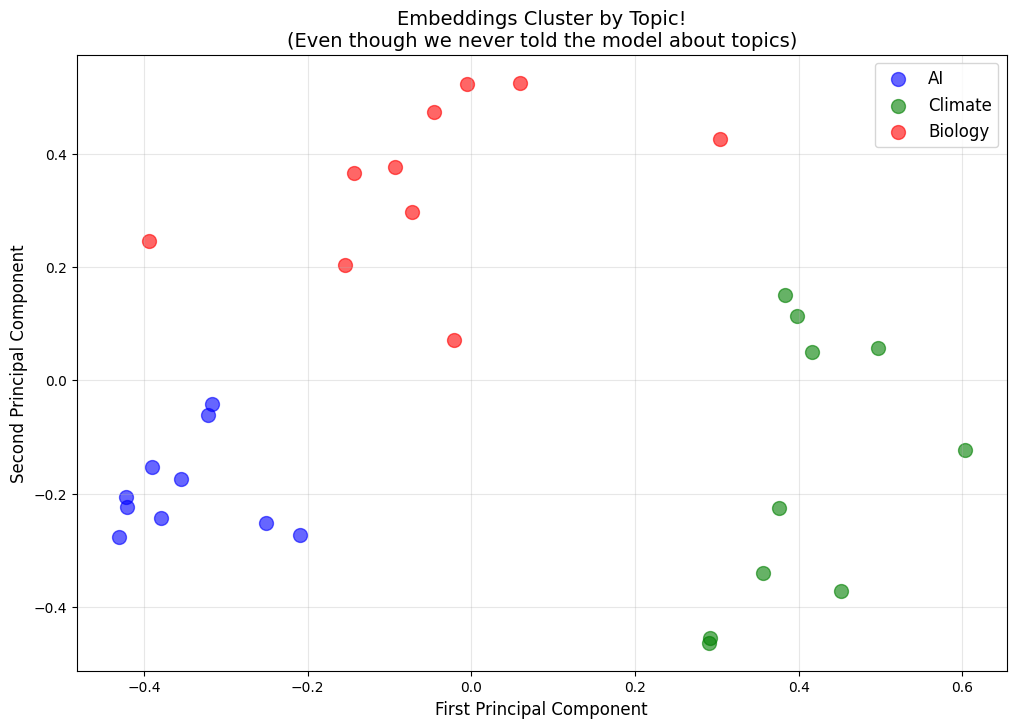


💡 Key Insight: Similar topics naturally cluster together in embedding space!
This is what FAISS exploits to speed up search.


In [6]:
from sklearn.decomposition import PCA

# Reduce to 2D for visualization
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

# Color by topic
colors = {'AI': 'blue', 'Climate': 'green', 'Biology': 'red'}
chunk_colors = [colors[chunk['metadata']['topic']] for chunk in chunks]

# Plot
plt.figure(figsize=(12, 8))
for topic, color in colors.items():
    mask = [chunk['metadata']['topic'] == topic for chunk in chunks]
    plt.scatter(
        embeddings_2d[mask, 0],
        embeddings_2d[mask, 1],
        c=color,
        label=topic,
        s=100,
        alpha=0.6
    )

plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('Embeddings Cluster by Topic!\n(Even though we never told the model about topics)', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

print("\n💡 Key Insight: Similar topics naturally cluster together in embedding space!")
print("This is what FAISS exploits to speed up search.")

## 🤔 Comprehension Check #1

Look at the plot above.

**Q1**: Why do you think AI-related chunks are close to each other in the plot?

**Q2**: If you wanted to find chunks about "deep learning", which region of the plot would you search? Why would this be faster than searching everywhere?

**Think about this before continuing!**

## Step 5: Brute Force Search (Baseline)

Let's implement brute force search to see how it works.

In [7]:
def brute_force_search(query_embedding, chunk_embeddings, chunks, k=3):
    """
    Search by comparing query to EVERY chunk embedding.
    """
    similarities = []
    
    # Compare to every single embedding
    for i, chunk_emb in enumerate(chunk_embeddings):
        # Calculate cosine similarity (dot product since embeddings are normalized)
        similarity = float(np.dot(query_embedding, chunk_emb))
        similarities.append((similarity, i))
    
    # Sort by similarity (highest first)
    similarities.sort(reverse=True)
    
    # Return top k
    results = []
    for score, idx in similarities[:k]:
        results.append({
            'chunk': chunks[idx],
            'score': score,
            'index': idx
        })
    
    return results

# Test it
query = "How do neural networks work?"
query_embedding = embedder.encode(query)

start = time.time()
results = brute_force_search(query_embedding, embeddings, chunks, k=3)
brute_time = time.time() - start

print(f"Query: '{query}'\n")
print(f"Brute Force Search Results (checked ALL {len(chunks)} chunks):")
print(f"Time taken: {brute_time*1000:.2f} milliseconds\n")

for i, result in enumerate(results, 1):
    print(f"{i}. Score: {result['score']:.3f}")
    print(f"   {result['chunk']['text']}")
    print(f"   Topic: {result['chunk']['metadata']['topic']}\n")

Query: 'How do neural networks work?'

Brute Force Search Results (checked ALL 30 chunks):
Time taken: 0.00 milliseconds

1. Score: 0.611
   Deep learning uses neural networks with multiple layers.
   Topic: AI

2. Score: 0.451
   Neurons transmit electrical signals in the brain.
   Topic: Biology

3. Score: 0.450
   Convolutional neural networks excel at image recognition.
   Topic: AI



## Step 6: FAISS Search (Your retriever.py)

Now let's use your `FAISSRetriever` class!

In [8]:
# Initialize FAISS retriever with Flat index (exact search)
retriever = FAISSRetriever(
    embedding_dimension=embeddings.shape[1],
    index_type="Flat"  # Exact search (same as brute force, but optimized)
)

# Add documents
retriever.add_documents(chunks, embeddings)

print(f"✅ Added {len(chunks)} documents to FAISS index")
print(f"Index stats: {retriever.get_stats()}")

INFO:src.models.retriever:Initialized FAISS Flat index with dimension 384
INFO:src.models.retriever:Added 30 documents. Total documents in index: 30


✅ Added 30 documents to FAISS index
Index stats: {'num_documents': 30, 'embedding_dimension': 384, 'index_type': 'Flat', 'is_trained': False}


In [9]:
# Search using FAISS
start = time.time()
faiss_results = retriever.search(query_embedding, k=3)
faiss_time = time.time() - start

print(f"Query: '{query}'\n")
print(f"FAISS Search Results:")
print(f"Time taken: {faiss_time*1000:.2f} milliseconds\n")

for i, result in enumerate(faiss_results, 1):
    print(f"{i}. Score: {result['score']:.3f}")
    print(f"   {result['chunk']['text']}")
    print(f"   Topic: {result['chunk']['metadata']['topic']}\n")

print(f"\n⚡ Speed comparison:")
print(f"Brute force: {brute_time*1000:.2f}ms")
print(f"FAISS Flat:  {faiss_time*1000:.2f}ms")
print(f"\nNote: With only 30 chunks, the difference is small.")
print(f"With 100,000+ chunks, FAISS becomes MUCH faster!")

INFO:src.models.retriever:Retrieved 3 results for query


Query: 'How do neural networks work?'

FAISS Search Results:
Time taken: 7.05 milliseconds

1. Score: 0.805
   Deep learning uses neural networks with multiple layers.
   Topic: AI

2. Score: 0.725
   Neurons transmit electrical signals in the brain.
   Topic: Biology

3. Score: 0.725
   Convolutional neural networks excel at image recognition.
   Topic: AI


⚡ Speed comparison:
Brute force: 0.00ms
FAISS Flat:  7.05ms

Note: With only 30 chunks, the difference is small.
With 100,000+ chunks, FAISS becomes MUCH faster!


## Step 7: Understanding Index Types

Your `retriever.py` supports two index types:

### 1. **IndexFlatL2** (What we just used)
- **How it works**: Brute force comparison (checks every embedding)
- **Accuracy**: 100% - finds the true nearest neighbors
- **Speed**: Slower for large datasets
- **Best for**: <10,000 chunks, when accuracy is critical

### 2. **IndexIVFFlat** (Available in your code)
- **How it works**: Clusters embeddings into groups (like warehouse aisles!)
- **Accuracy**: 95-99% - might miss some true neighbors
- **Speed**: Much faster for large datasets
- **Best for**: >10,000 chunks, when speed matters

Let's visualize how IVF clustering works!

c:\Users\jainv\AppData\Local\Programs\Python\Python38\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\jainv\AppData\Local\Programs\Python\Python38\lib\site-packages\threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


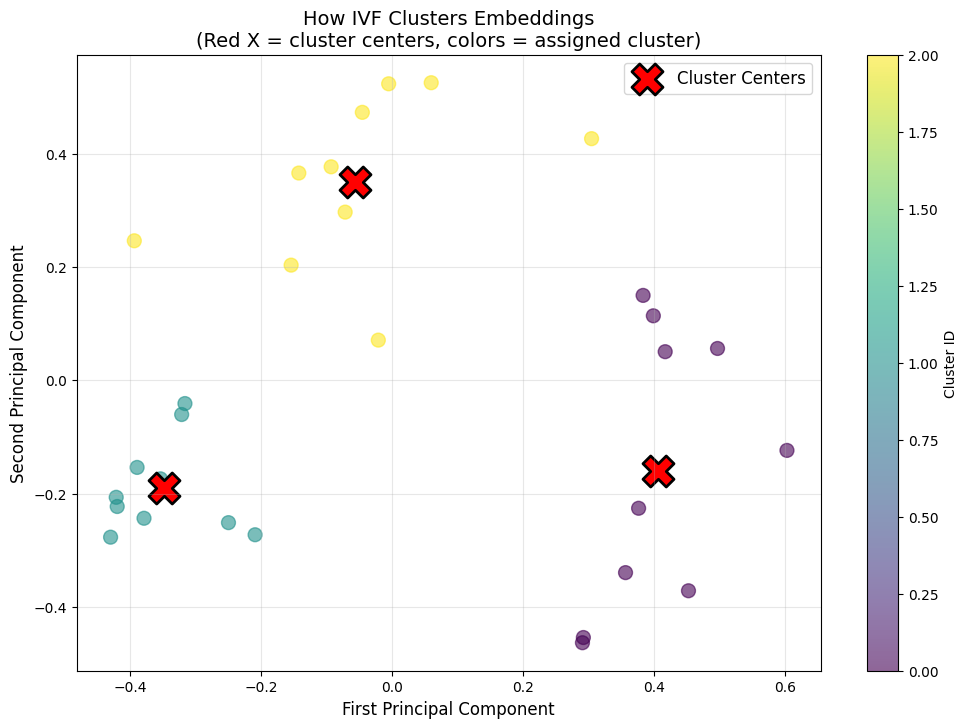


💡 How IVF Search Works:
1. During indexing: Cluster all embeddings (like organizing warehouse aisles)
2. During search:
   a) Find which cluster(s) the query is closest to
   b) Only search embeddings in those cluster(s)
   c) Skip all other clusters!

   Example: Instead of searching 1 million chunks,
            search only ~10,000 chunks in the nearest cluster(s)
            = 100x speedup! ⚡


In [10]:
# Simulate IVF clustering using KMeans
n_clusters = 3  # In real IVF, this would be ~100 for large datasets
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(embeddings)

# Visualize clusters
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=100,
    alpha=0.6
)

# Plot cluster centers
centers_2d = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centers_2d[:, 0],
    centers_2d[:, 1],
    c='red',
    marker='X',
    s=500,
    edgecolors='black',
    linewidths=2,
    label='Cluster Centers'
)

plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('How IVF Clusters Embeddings\n(Red X = cluster centers, colors = assigned cluster)', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.colorbar(scatter, label='Cluster ID')
plt.show()

print("\n💡 How IVF Search Works:")
print("1. During indexing: Cluster all embeddings (like organizing warehouse aisles)")
print("2. During search:")
print("   a) Find which cluster(s) the query is closest to")
print("   b) Only search embeddings in those cluster(s)")
print("   c) Skip all other clusters!")
print("\n   Example: Instead of searching 1 million chunks,")
print("            search only ~10,000 chunks in the nearest cluster(s)")
print("            = 100x speedup! ⚡")

## 🤔 Comprehension Check #2

**Q1**: Looking at the cluster visualization above, if your query is about "climate change", which cluster(s) would IVF search? Why is this faster than searching all clusters?

**Q2**: Can you think of a scenario where IVF might miss a relevant result? (Hint: What if a relevant chunk is on the edge of a different cluster?)

**Q3**: When would you use IndexFlatL2 vs IndexIVFFlat in a real project?

**Think about these before continuing!**

## Step 8: Save and Load Index

In production, you don't want to rebuild the index every time!

Your `retriever.py` has `save()` and `load()` methods.

In [11]:
# Save the index
save_path = "../data/test_index"
retriever.save(save_path)

print(f"✅ Saved index to {save_path}")
print("\nFiles created:")
import os
for file in os.listdir(save_path):
    print(f"  - {file}")

INFO:src.models.retriever:Saved retriever to ../data/test_index


✅ Saved index to ../data/test_index

Files created:
  - chunks.pkl
  - config.pkl
  - index.faiss


In [12]:
# Load the index
loaded_retriever = FAISSRetriever.load(save_path)

print(f"✅ Loaded index from {save_path}")
print(f"Stats: {loaded_retriever.get_stats()}")

# Test that it works
test_results = loaded_retriever.search(query_embedding, k=3)
print(f"\nTest search successful! Found {len(test_results)} results")
print(f"Top result: {test_results[0]['chunk']['text'][:80]}...")

INFO:src.models.retriever:Initialized FAISS Flat index with dimension 384
INFO:src.models.retriever:Loaded retriever from ../data/test_index (30 documents)
INFO:src.models.retriever:Retrieved 3 results for query


✅ Loaded index from ../data/test_index
Stats: {'num_documents': 30, 'embedding_dimension': 384, 'index_type': 'Flat', 'is_trained': False}

Test search successful! Found 3 results
Top result: Deep learning uses neural networks with multiple layers....


## 🧪 Your Turn: Experiments!

### Exercise 1: Try Different Queries
Search for:
- A climate question: "How does CO2 affect temperature?"
- A biology question: "What is DNA's role?"
- A cross-domain question: "How is AI used in biology?"

See which results you get!

### Exercise 2: Scale Test
Create a larger dataset (duplicate the chunks 100x) and compare:
- IndexFlatL2 speed
- IndexIVFFlat speed

Which is faster for 3,000 chunks?

### Exercise 3: Understand Your Code
Go to `src/models/retriever.py` and read through:
- The `add_documents()` method - what does it do?
- The `search()` method - how does it convert distances to similarity scores?
- The `save()` and `load()` methods - what files are saved?

**Write your experiments below!**

In [ ]:
# Your experimentation space!



## 📚 Key Takeaways

By now you should understand:

1. ✅ **Brute force search** compares query to every embedding (slow for large datasets)
2. ✅ **FAISS** organizes embeddings for faster search
3. ✅ **IndexFlatL2**: Exact search, 100% accurate, slower
4. ✅ **IndexIVFFlat**: Cluster-based search, ~99% accurate, much faster
5. ✅ **Trade-off**: Speed vs Accuracy
6. ✅ **Your retriever.py** abstracts all this complexity!

---

## 🤔 Final Comprehension Questions

**Q1**: Explain the "warehouse analogy" for FAISS in your own words.

**Q2**: When would you choose IndexFlatL2 over IndexIVFFlat?

**Q3**: Looking at your `src/models/retriever.py` - can you now explain:
- Why embeddings need to be converted to `float32`?
- What the `is_trained` flag is for in IVF?
- How the similarity score is calculated from L2 distance?

---

**Next Module**: We'll learn how the LLM uses retrieved chunks to generate answers!